# Step 4: Professional EDA of the complete `static_0` table

This notebook audits **all 167 predictor columns** in `static_0`, while providing deeper visual analysis for a smaller set of understandable features. It answers five questions:

1. Is the table structurally safe to join to the application base?
2. Which columns are complete, constant, sparse, or unusually concentrated?
3. What do numerical, categorical, Boolean, and date values look like?
4. Which features show an association with default in the development period?
5. Which features change as time moves forward?

**Guardrails:** EDA flags possible problems; it does not automatically delete rows, cap outliers, fill missing values, encode categories, or scale features. Those transformations must be learned inside each future training fold. Large values and missing values may be valid credit information.

## 4.1 Setup and reproducibility

The full table is used for exact structural and missing-value counts. A fixed sample from the development period is used for computationally heavier charts and exploratory target comparisons. This keeps the notebook practical on a laptop with 20 GB RAM.

In [1]:
from pathlib import Path
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pyarrow as pa
import pyarrow.parquet as pq
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score

RANDOM_STATE = 42
EDA_SAMPLE_SIZE = 200_000
CORRELATION_SAMPLE_SIZE = 50_000
FINAL_HOLDOUT_WEEKS = 20

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

project_dir = Path(r"D:\Home Credit - Credit Risk Model Stability")
train_dir = project_dir / "data" / "parquet_files" / "train"
report_dir = project_dir / "reports" / "static_0_eda"
report_dir.mkdir(parents=True, exist_ok=True)

base_path = train_dir / "train_base.parquet"
static_paths = [
    train_dir / "train_static_0_0.parquet",
    train_dir / "train_static_0_1.parquet",
]
definitions_path = project_dir / "data" / "feature_definitions.csv"

required_paths = [base_path, definitions_path, *static_paths]
missing_files = [str(path) for path in required_paths if not path.exists()]
assert not missing_files, f"Required files are missing: {missing_files}"
print("Setup complete.")

Setup complete.


## 4.2 Audit the two physical files before loading them

The two files are row partitions of one logical table. We first confirm that they have identical schemas. The trailing letter is a competition naming convention; the supplied feature dictionary remains the primary source for interpreting each feature.

In [2]:
schemas = [pq.read_schema(path) for path in static_paths]
assert schemas[0].equals(schemas[1]), "The static file schemas do not match."

file_audit = pd.DataFrame([
    {
        "file": path.name,
        "rows": pq.ParquetFile(path).metadata.num_rows,
        "columns": len(schema),
        "size_MB": path.stat().st_size / 1_000_000,
    }
    for path, schema in zip(static_paths, schemas)
])

arrow_type_counts = (
    pd.Series([str(field.type) for field in schemas[0]], name="columns")
    .value_counts()
    .rename_axis("Arrow type")
    .to_frame()
)
suffix_counts = (
    pd.Series([name[-1] for name in schemas[0].names if name != "case_id"], name="features")
    .value_counts()
    .sort_index()
    .rename_axis("suffix")
    .to_frame()
)

display(file_audit.style.format({"rows": "{:,}", "size_MB": "{:.1f}"}))
display(arrow_type_counts)
display(suffix_counts.T)

,file,rows,columns,size_MB
0,train_static_0_0.parquet,"1,003,757",168,113.9
1,train_static_0_1.parquet,"522,902",168,74.7


,count
Arrow type,
double,128
string,33
bool,6
int64,1


suffix,A,D,L,M,P
count,31,15,91,8,22


## 4.3 Load, combine, type, and join the data

Dates are converted to `datetime`, text categories to pandas `category`, and nullable Boolean columns to the Boolean extension type. These conversions preserve meaning and substantially reduce memory usage.

In [3]:
schema = schemas[0]
date_columns = [
    field.name for field in schema
    if pa.types.is_string(field.type) and field.name.endswith("D")
]
text_columns = [
    field.name for field in schema
    if pa.types.is_string(field.type) and field.name not in date_columns
]
boolean_columns = [field.name for field in schema if pa.types.is_boolean(field.type)]

static_parts = [pd.read_parquet(path) for path in static_paths]
raw_memory_gib = sum(
    part.memory_usage(deep=True).sum() for part in static_parts
) / 1024**3
static_data = pd.concat(static_parts, ignore_index=True)
del static_parts
gc.collect()

for column in date_columns:
    static_data[column] = pd.to_datetime(static_data[column], errors="coerce")
for column in text_columns:
    static_data[column] = static_data[column].astype("category")
for column in boolean_columns:
    static_data[column] = static_data[column].astype("boolean")

typed_memory_gib = static_data.memory_usage(deep=True).sum() / 1024**3

base = pd.read_parquet(
    base_path,
    columns=["case_id", "date_decision", "MONTH", "WEEK_NUM", "target"],
)
base["date_decision"] = pd.to_datetime(base["date_decision"], format="%Y-%m-%d")

duplicate_static_ids = int(static_data["case_id"].duplicated().sum())
duplicate_base_ids = int(base["case_id"].duplicated().sum())
static_ids_not_in_base = int((~static_data["case_id"].isin(base["case_id"])).sum())
base_ids_without_static = int((~base["case_id"].isin(static_data["case_id"])).sum())

assert duplicate_static_ids == 0
assert duplicate_base_ids == 0

data = base.merge(
    static_data, on="case_id", how="left", validate="one_to_one"
)
assert len(data) == len(base)

del static_data, base
gc.collect()

print(f"Raw pandas memory before type optimization: {raw_memory_gib:.2f} GiB")
print(f"Typed static table memory: {typed_memory_gib:.2f} GiB")
print(f"Joined table: {data.shape[0]:,} rows × {data.shape[1]:,} columns")
print(f"Duplicate static IDs: {duplicate_static_ids:,}")
print(f"Static IDs absent from base: {static_ids_not_in_base:,}")
print(f"Base IDs without static data: {base_ids_without_static:,}")

Raw pandas memory before type optimization: 3.77 GiB
Typed static table memory: 1.68 GiB
Joined table: 1,526,659 rows × 172 columns
Duplicate static IDs: 0
Static IDs absent from base: 0
Base IDs without static data: 0


## 4.4 Reserve a final time holdout before target-aware EDA

The final twenty weeks (72–91) are reserved for later model evaluation. Their targets are not used in feature-versus-target comparisons here. Quality checks that do not use `target` may still examine all rows.

This does not replace time-aware cross-validation; it preserves one final, later period for an honest check after model development.

In [4]:
maximum_week = int(data["WEEK_NUM"].max())
holdout_start_week = maximum_week - FINAL_HOLDOUT_WEEKS + 1
development_mask = data["WEEK_NUM"] < holdout_start_week
holdout_mask = ~development_mask

development_indices = np.flatnonzero(development_mask.to_numpy())
rng = np.random.default_rng(RANDOM_STATE)
sample_size = min(EDA_SAMPLE_SIZE, len(development_indices))
sample_indices = rng.choice(development_indices, size=sample_size, replace=False)
eda_sample = data.iloc[sample_indices].copy()
association_train_mask = eda_sample["WEEK_NUM"] <= 51
association_valid_mask = eda_sample["WEEK_NUM"].between(52, 71)
assert association_train_mask.any() and association_valid_mask.any()

feature_columns = [
    column for column in schema.names if column != "case_id"
]
numeric_columns = [
    field.name for field in schema if pa.types.is_floating(field.type)
]
categorical_columns = text_columns + boolean_columns

split_summary = pd.DataFrame({
    "period": ["Development", "Final holdout", "EDA sample (development only)"],
    "rows": [int(development_mask.sum()), int(holdout_mask.sum()), len(eda_sample)],
    "first_week": [int(data.loc[development_mask, "WEEK_NUM"].min()), holdout_start_week, int(eda_sample["WEEK_NUM"].min())],
    "last_week": [holdout_start_week - 1, maximum_week, int(eda_sample["WEEK_NUM"].max())],
})
display(split_summary.style.format({"rows": "{:,}"}))
print(f"Association-learning sample rows (weeks 0–51): {association_train_mask.sum():,}")
print(f"Association-validation sample rows (weeks 52–71): {association_valid_mask.sum():,}")
print(f"Predictors: {len(feature_columns)} = {len(numeric_columns)} numeric + {len(date_columns)} date + {len(categorical_columns)} categorical/Boolean")

,period,rows,first_week,last_week
0,Development,"1,314,456",0,71
1,Final holdout,"212,203",72,91
2,EDA sample (development only),"200,000",0,71


Association-learning sample rows (weeks 0–51): 162,043
Association-validation sample rows (weeks 52–71): 37,957
Predictors: 167 = 128 numeric + 15 date + 24 categorical/Boolean


## 4.5 Create a searchable catalog for every feature

The catalog combines the official description with observed data quality. Missing counts and unique counts use the complete table. Dominant-value percentage uses the fixed development sample and is marked accordingly.

In [5]:
definitions = pd.read_csv(definitions_path)
description_map = definitions.set_index("Variable")["Description"].to_dict()

def feature_kind(column):
    if column in date_columns:
        return "date"
    if column in boolean_columns:
        return "boolean"
    if column in text_columns:
        return "categorical"
    return "numeric"

catalog_rows = []
for column in feature_columns:
    full_series = data[column]
    sample_counts = eda_sample[column].value_counts(dropna=False, normalize=True)
    catalog_rows.append({
        "feature": column,
        "description": description_map.get(column, "Description unavailable"),
        "suffix": column[-1],
        "kind": feature_kind(column),
        "pandas_dtype": str(full_series.dtype),
        "non_null_count": int(full_series.notna().sum()),
        "missing_count": int(full_series.isna().sum()),
        "missing_percent": float(full_series.isna().mean() * 100),
        "unique_non_null": int(full_series.nunique(dropna=True)),
        "sample_dominant_percent": float(sample_counts.iloc[0] * 100) if len(sample_counts) else np.nan,
    })

feature_catalog = pd.DataFrame(catalog_rows).set_index("feature")

catalog_overview = pd.DataFrame({
    "features": feature_catalog.groupby("kind").size(),
    "median_missing_percent": feature_catalog.groupby("kind")["missing_percent"].median(),
    "maximum_missing_percent": feature_catalog.groupby("kind")["missing_percent"].max(),
}).sort_index()
display(catalog_overview.round(2))
display(feature_catalog.head(10).style.format({
    "non_null_count": "{:,}",
    "missing_count": "{:,}",
    "missing_percent": "{:.2f}%",
    "sample_dominant_percent": "{:.2f}%",
}))

,features,median_missing_percent,maximum_missing_percent
kind,,,
boolean,6,91.15,99.18
categorical,18,0.00,87.44
date,15,56.28,99.84
numeric,128,29.06,99.97


,description,suffix,kind,pandas_dtype,non_null_count,missing_count,missing_percent,unique_non_null,sample_dominant_percent
feature,,,,,,,,,
actualdpdtolerance_344P,DPD of client with tolerance.,P,numeric,float64,"1,108,481","418,178",27.39%,170,71.31%
amtinstpaidbefduel24m_4187115A,Number of instalments paid before due date in the last 24 months.,A,numeric,float64,"965,535","561,124",36.76%,610152,38.92%
annuity_780A,Monthly annuity amount.,A,numeric,float64,"1,526,659",0,0.00%,75325,0.83%
annuitynextmonth_57A,Next month's amount of annuity.,A,numeric,float64,"1,526,655",4,0.00%,66202,69.63%
applicationcnt_361L,Number of applications associated with the same email address as the client.,L,numeric,float64,"1,526,659",0,0.00%,5,100.00%
applications30d_658L,Number of applications made by the client in the last 30 days.,L,numeric,float64,"1,526,659",0,0.00%,25,89.78%
applicationscnt_1086L,Number of applications associated with the same phone number.,L,numeric,float64,"1,526,659",0,0.00%,125,94.57%
applicationscnt_464L,Number of applications made in the last 30 days by other clients with the same employer as the applicant.,L,numeric,float64,"1,526,659",0,0.00%,248,90.03%
applicationscnt_629L,Number of applications with the same employer in the last 7 days.,L,numeric,float64,"1,526,659",0,0.00%,90,94.13%


## 4.6 Missingness, constant columns, and concentration

A missing value can represent unavailable information, no applicable history, or a collection problem. High missingness is an investigation priority, not an automatic reason to drop a feature. A feature dominated by one value may still help with rare cases, but it needs careful validation.

Fully missing features: 0
Features with one observed value (some may still signal through missingness): 10
Complete constants with no missingness signal: 1
Approximately ≥99.5% one value in sample: 13


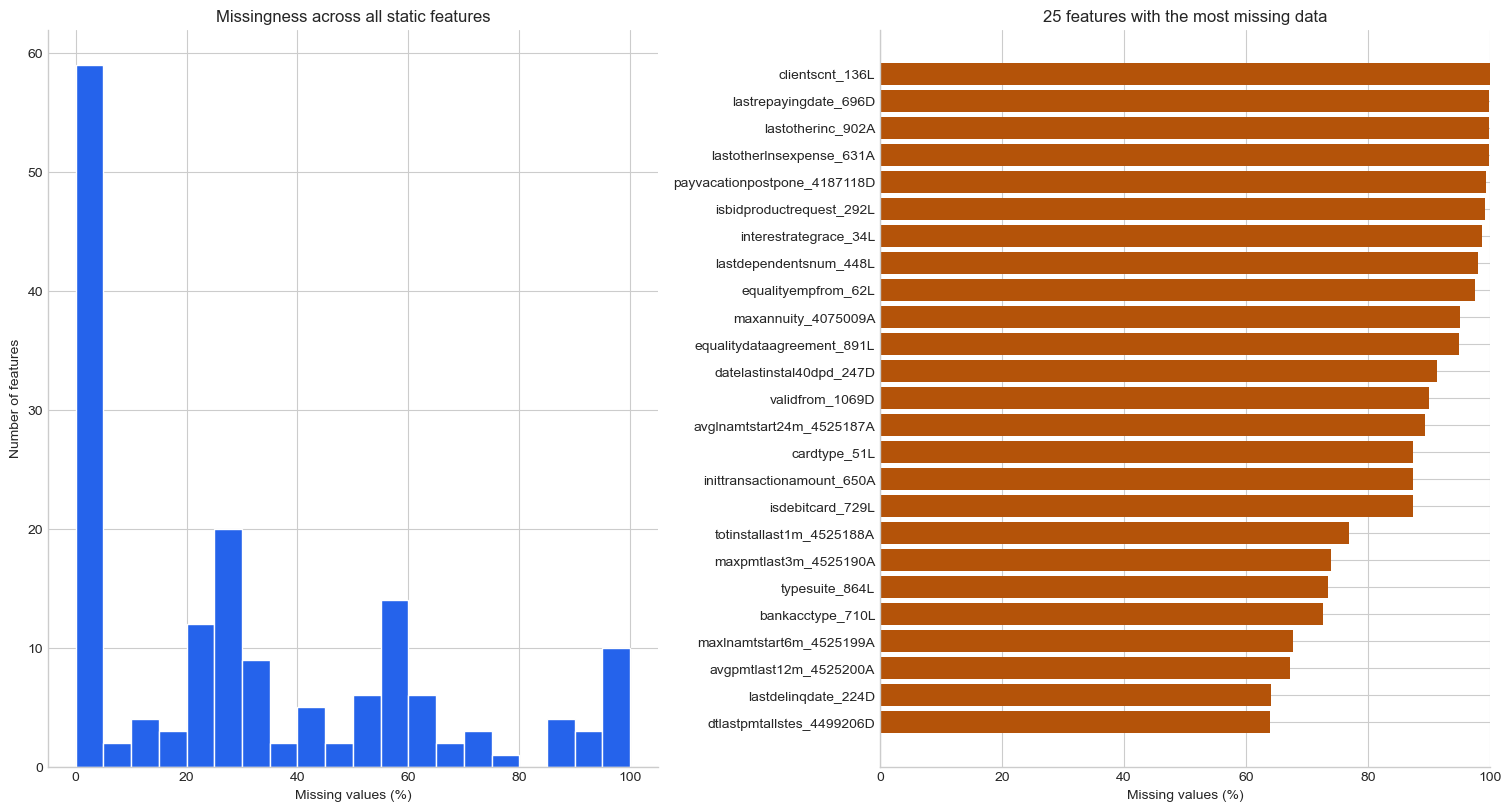

,description,kind,missing_count,missing_percent,unique_non_null
feature,,,,,
clientscnt_136L,Number of applications associated with same email address as client's email.,numeric,"1,526,242",99.97%,5
lastrepayingdate_696D,Date of the last payment made by the applicant.,date,"1,524,282",99.84%,539
lastotherinc_902A,Amount of other income reported by the client in their last application.,numeric,"1,523,603",99.80%,101
lastotherlnsexpense_631A,Monthly expenses on other loans from the last application.,numeric,"1,523,601",99.80%,232
payvacationpostpone_4187118D,Date of last payment holiday instalment.,date,"1,517,330",99.39%,596
isbidproductrequest_292L,Flag indicating if the product is a cross-sell.,boolean,"1,514,201",99.18%,2
interestrategrace_34L,Interest rate during the grace period.,numeric,"1,505,776",98.63%,1
lastdependentsnum_448L,Number of dependents in the client's last loan application.,numeric,"1,497,142",98.07%,13
equalityempfrom_62L,Flag indicating a sudden change in the client's length of employment.,boolean,"1,488,847",97.52%,2


In [6]:
fully_missing_features = feature_catalog.index[feature_catalog["missing_percent"] == 100].tolist()
single_observed_value_features = feature_catalog.index[feature_catalog["unique_non_null"] <= 1].tolist()
complete_constant_features = feature_catalog.index[
    (feature_catalog["unique_non_null"] <= 1)
    & (feature_catalog["missing_percent"] == 0)
].tolist()
near_constant_features = feature_catalog.index[feature_catalog["sample_dominant_percent"] >= 99.5].tolist()

print(f"Fully missing features: {len(fully_missing_features)}")
print(f"Features with one observed value (some may still signal through missingness): {len(single_observed_value_features)}")
print(f"Complete constants with no missingness signal: {len(complete_constant_features)}")
print(f"Approximately ≥99.5% one value in sample: {len(near_constant_features)}")

top_missing = feature_catalog.nlargest(25, "missing_percent").sort_values("missing_percent")
fig, axes = plt.subplots(1, 2, figsize=(15, 8), layout="constrained")
axes[0].hist(feature_catalog["missing_percent"], bins=np.arange(0, 105, 5), color="#2563EB", edgecolor="white")
axes[0].set(title="Missingness across all static features", xlabel="Missing values (%)", ylabel="Number of features")
axes[1].barh(top_missing.index, top_missing["missing_percent"], color="#B45309")
axes[1].set(title="25 features with the most missing data", xlabel="Missing values (%)")
axes[1].set_xlim(0, 100)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.show()
plt.close(fig)

display(feature_catalog.nlargest(20, "missing_percent")[
    ["description", "kind", "missing_count", "missing_percent", "unique_non_null"]
].style.format({"missing_count": "{:,}", "missing_percent": "{:.2f}%"}))

### Does missingness carry information about default?

For each feature, we compare default rates when the value is missing versus observed. This is exploratory and uses only the development sample. A difference does not prove causation and must later survive time-aware validation.

In [7]:
def safe_binary_auc(target, score):
    target = np.asarray(target)
    score = np.asarray(score, dtype=float)
    valid = np.isfinite(score)
    if valid.sum() == 0 or np.unique(target[valid]).size < 2 or np.unique(score[valid]).size < 2:
        return np.nan
    return roc_auc_score(target[valid], score[valid])

missing_signal_rows = []
for column in feature_columns:
    is_missing = eda_sample[column].isna().astype(int)
    train_indicator = is_missing[association_train_mask]
    valid_indicator = is_missing[association_valid_mask]
    y_train_period = eda_sample.loc[association_train_mask, "target"]
    y_valid_period = eda_sample.loc[association_valid_mask, "target"]

    train_auc = safe_binary_auc(y_train_period, train_indicator)
    direction = 1 if pd.isna(train_auc) or train_auc >= 0.5 else -1
    valid_auc_oriented = safe_binary_auc(y_valid_period, valid_indicator * direction)

    def rate_gap(mask):
        indicator = is_missing[mask]
        target = eda_sample.loc[mask, "target"]
        if indicator.nunique() < 2:
            return np.nan
        return (target[indicator == 1].mean() - target[indicator == 0].mean()) * 100

    missing_signal_rows.append({
        "feature": column,
        "sample_missing_rows_train": int(train_indicator.sum()),
        "sample_missing_rows_valid": int(valid_indicator.sum()),
        "missing_rate_train_percent": float(train_indicator.mean() * 100),
        "missing_rate_valid_percent": float(valid_indicator.mean() * 100),
        "missing_rate_change_pp": float((valid_indicator.mean() - train_indicator.mean()) * 100),
        "missing_target_gap_train_pp": rate_gap(association_train_mask),
        "missing_target_gap_valid_pp": rate_gap(association_valid_mask),
        "missing_indicator_auc_train": train_auc,
        "missing_indicator_auc_valid_oriented": valid_auc_oriented,
    })

missing_target_signal = pd.DataFrame(missing_signal_rows).set_index("feature")
missing_target_signal["absolute_valid_gap_pp"] = missing_target_signal["missing_target_gap_valid_pp"].abs()

display(missing_target_signal.nlargest(20, "absolute_valid_gap_pp")[
    ["sample_missing_rows_valid", "missing_rate_change_pp", "missing_target_gap_train_pp", "missing_target_gap_valid_pp", "missing_indicator_auc_valid_oriented"]
].style.format({
    "sample_missing_rows_valid": "{:,}",
    "missing_rate_change_pp": "{:+.2f}",
    "missing_target_gap_train_pp": "{:+.2f}",
    "missing_target_gap_valid_pp": "{:+.2f}",
    "missing_indicator_auc_valid_oriented": "{:.3f}",
}))

,sample_missing_rows_valid,missing_rate_change_pp,missing_target_gap_train_pp,missing_target_gap_valid_pp,missing_indicator_auc_valid_oriented
feature,,,,,
twobodfilling_608L,2,+0.00,-3.07,+45.77,0.500
disbursementtype_67L,9,-0.02,+0.88,+18.00,0.501
lastrepayingdate_696D,"37,897",+0.01,-4.80,-17.47,0.503
datelastinstal40dpd_247D,"33,887",-3.53,-5.23,-5.83,0.569
lastotherlnsexpense_631A,"37,897",+0.06,+0.49,+4.24,0.501
lastotherinc_902A,"37,899",+0.06,+0.50,+4.23,0.501
clientscnt_136L,"37,955",+0.03,-3.83,+4.23,0.500
lastdelinqdate_224D,"22,973",-6.05,-1.98,-3.15,0.593
lastrejectcredamount_222A,"17,373",-7.07,-1.94,-3.08,0.595


## 4.7 Numerical distributions and possible outliers

For every numerical feature we calculate robust percentiles on the development sample and exact full-data counts of zero, negative, and infinite values. The IQR rule is a screening tool: credit amounts and behavioral counts are often naturally skewed, so an IQR flag is not proof of an error.

In [8]:
numeric_profile_rows = []
for column in numeric_columns:
    full_values = data[column].to_numpy(dtype="float64", copy=False)
    sample_values = eda_sample[column].to_numpy(dtype="float64", copy=False)
    finite_sample = sample_values[np.isfinite(sample_values)]
    finite_full = full_values[np.isfinite(full_values)]

    if len(finite_sample):
        q01, q05, q25, q50, q75, q95, q99 = np.quantile(
            finite_sample, [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
        )
        iqr = q75 - q25
        lower_bound, upper_bound = q25 - 1.5 * iqr, q75 + 1.5 * iqr
        iqr_outlier_percent = np.mean(
            (finite_sample < lower_bound) | (finite_sample > upper_bound)
        ) * 100
    else:
        q01 = q05 = q25 = q50 = q75 = q95 = q99 = np.nan
        iqr = lower_bound = upper_bound = iqr_outlier_percent = np.nan

    numeric_profile_rows.append({
        "feature": column,
        "full_min": np.min(finite_full) if len(finite_full) else np.nan,
        "sample_p01": q01,
        "sample_p05": q05,
        "sample_p25": q25,
        "sample_median": q50,
        "sample_p75": q75,
        "sample_p95": q95,
        "sample_p99": q99,
        "full_max": np.max(finite_full) if len(finite_full) else np.nan,
        "zero_percent_full": np.mean(full_values == 0) * 100,
        "negative_percent_full": np.mean(full_values < 0) * 100,
        "infinite_count_full": int(np.isinf(full_values).sum()),
        "sample_iqr_outlier_percent": iqr_outlier_percent,
    })

numeric_profile = pd.DataFrame(numeric_profile_rows).set_index("feature")
display(numeric_profile.head(15).style.format(precision=2))
print(f"Numerical features containing infinity: {(numeric_profile['infinite_count_full'] > 0).sum()}")
print(f"Numerical features containing negative values: {(numeric_profile['negative_percent_full'] > 0).sum()}")

,full_min,sample_p01,sample_p05,sample_p25,sample_median,sample_p75,sample_p95,sample_p99,full_max,zero_percent_full,negative_percent_full,infinite_count_full,sample_iqr_outlier_percent
feature,,,,,,,,,,,,,
actualdpdtolerance_344P,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,4206.00,72.35,0.00,0,0.37
amtinstpaidbefduel24m_4187115A,0.00,0.00,0.00,6977.85,28294.40,72150.84,197794.18,308731.78,1408010.20,10.55,0.00,0,7.11
annuity_780A,80.80,689.80,1093.40,1915.60,3054.40,5073.60,9557.05,14403.42,106007.00,0.00,0.00,0,4.66
annuitynextmonth_57A,0.00,0.00,0.00,0.00,0.00,1966.60,7329.60,11683.00,87500.00,69.40,0.00,0,10.95
applicationcnt_361L,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.00,100.00,0.00,0,0.00
applications30d_658L,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2.00,28.00,89.52,0.00,0,10.22
applicationscnt_1086L,0.00,0.00,0.00,0.00,0.00,0.00,1.00,12.00,728.00,94.76,0.00,0,5.43
applicationscnt_464L,0.00,0.00,0.00,0.00,0.00,0.00,2.00,27.00,247.00,91.34,0.00,0,9.97
applicationscnt_629L,0.00,0.00,0.00,0.00,0.00,0.00,1.00,7.00,90.00,94.91,0.00,0,5.87


Numerical features containing infinity: 0
Numerical features containing negative values: 12


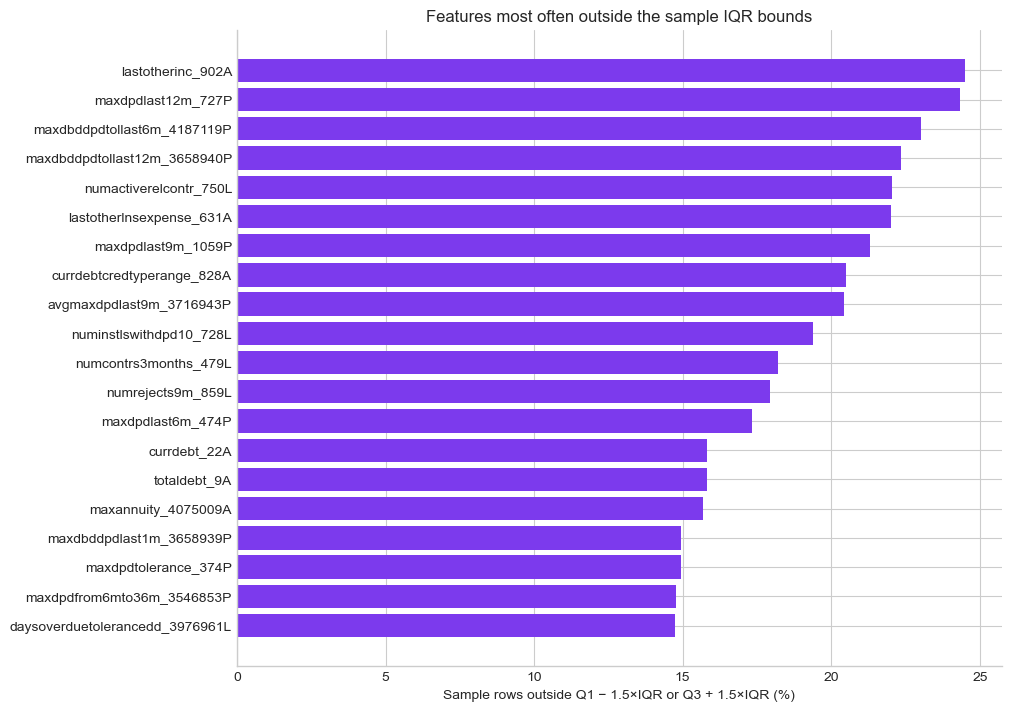

In [9]:
top_iqr_flags = numeric_profile.nlargest(20, "sample_iqr_outlier_percent").sort_values("sample_iqr_outlier_percent")
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.barh(top_iqr_flags.index, top_iqr_flags["sample_iqr_outlier_percent"], color="#7C3AED")
ax.set(title="Features most often outside the sample IQR bounds", xlabel="Sample rows outside Q1 − 1.5×IQR or Q3 + 1.5×IQR (%)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
plt.close(fig)

### Exploratory numerical relationship with target

A one-feature AUC asks whether one numerical column by itself tends to rank defaults differently from non-defaults. We learn whether high or low values indicate risk in weeks 0–51, lock that direction, and evaluate it in weeks 52–71. Missing rows are excluded here because missingness was evaluated separately. This is still a screening diagnostic, not multivariate model performance.

,observed_rows_train,observed_rows_valid,auc_train_raw,risk_direction_learned_train,auc_valid_oriented,valid_median_target_0,valid_median_target_1
feature,,,,,,,
pctinstlsallpaidlate1d_3546856L,"110,005","27,680",0.674,higher,0.672,0.08,0.26
avgdbddpdlast24m_3658932P,"93,483","24,099",0.672,higher,0.669,-5.00,-1.00
maxdbddpdtollast12m_3658940P,"84,211","21,811",0.691,higher,0.668,0.00,2.00
avgdbdtollast24m_4525197P,"38,766","24,096",0.675,higher,0.663,-5.00,-1.00
avgdpdtolclosure24_3658938P,"109,099","27,437",0.672,higher,0.662,0.00,1.00
pctinstlsallpaidlate4d_3546849L,"109,893","27,645",0.660,higher,0.655,0.02,0.15
daysoverduetolerancedd_3976961L,"110,634","27,892",0.651,higher,0.654,2.00,12.00
maxdbddpdtollast6m_4187119P,"63,482","19,348",0.682,higher,0.653,0.00,1.00
pctinstlsallpaidearl3d_427L,"110,005","27,680",0.342,lower,0.651,0.60,0.40


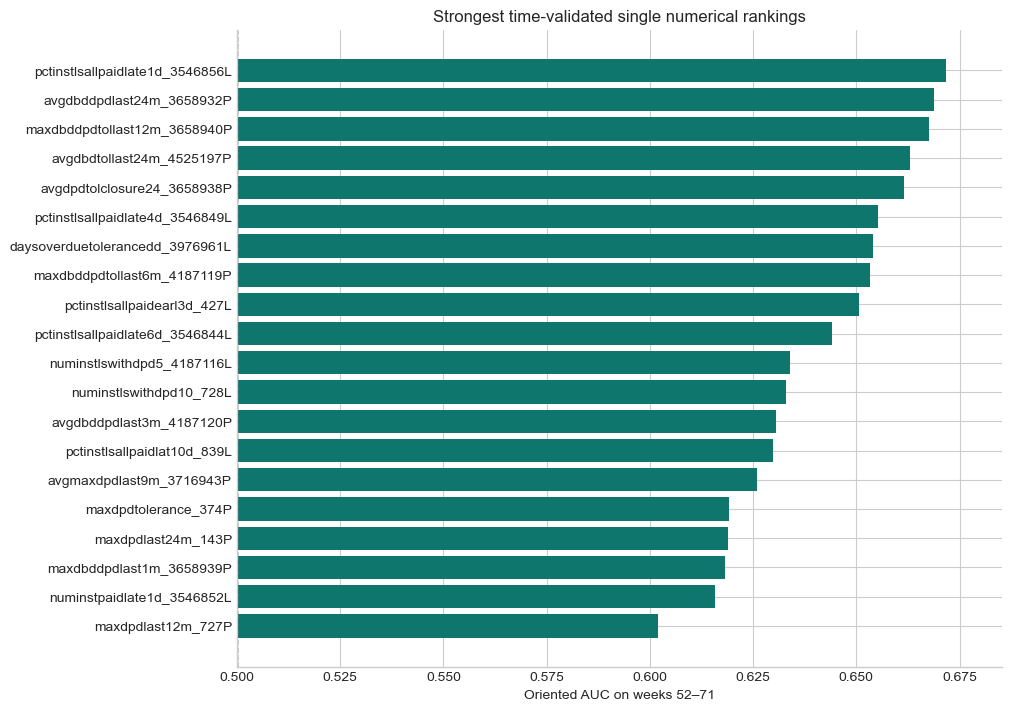

In [10]:
numeric_target_rows = []
for column in numeric_columns:
    values = eda_sample[column].astype("float64").replace([np.inf, -np.inf], np.nan)
    train_observed = association_train_mask & values.notna()
    valid_observed = association_valid_mask & values.notna()
    train_auc = safe_binary_auc(eda_sample.loc[train_observed, "target"], values[train_observed])
    direction = 1 if pd.isna(train_auc) or train_auc >= 0.5 else -1
    valid_auc_oriented = safe_binary_auc(
        eda_sample.loc[valid_observed, "target"], values[valid_observed] * direction
    )
    numeric_target_rows.append({
        "feature": column,
        "observed_rows_train": int(train_observed.sum()),
        "observed_rows_valid": int(valid_observed.sum()),
        "auc_train_raw": train_auc,
        "risk_direction_learned_train": "higher" if direction == 1 else "lower",
        "auc_valid_oriented": valid_auc_oriented,
        "valid_median_target_0": values[valid_observed & eda_sample["target"].eq(0)].median(),
        "valid_median_target_1": values[valid_observed & eda_sample["target"].eq(1)].median(),
    })

numeric_target_profile = pd.DataFrame(numeric_target_rows).set_index("feature")
top_numeric_signal = numeric_target_profile.nlargest(20, "auc_valid_oriented")
display(top_numeric_signal.style.format({
    "observed_rows_train": "{:,}",
    "observed_rows_valid": "{:,}",
    "auc_train_raw": "{:.3f}",
    "auc_valid_oriented": "{:.3f}",
    "valid_median_target_0": "{:,.2f}",
    "valid_median_target_1": "{:,.2f}",
}))

plot_data = top_numeric_signal.sort_values("auc_valid_oriented")
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.barh(plot_data.index, plot_data["auc_valid_oriented"], color="#0F766E")
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.set(title="Strongest time-validated single numerical rankings", xlabel="Oriented AUC on weeks 52–71", xlim=(0.5, max(0.51, plot_data['auc_valid_oriented'].max() * 1.02)))
ax.spines[["top", "right"]].set_visible(False)
plt.show()
plt.close(fig)

### Deep dive: ten understandable numerical features

Histograms are clipped only for display at the 1st and 99th sample percentiles; the underlying data is unchanged. The second figure groups each feature into quantile bins and displays the observed default rate in the development sample.

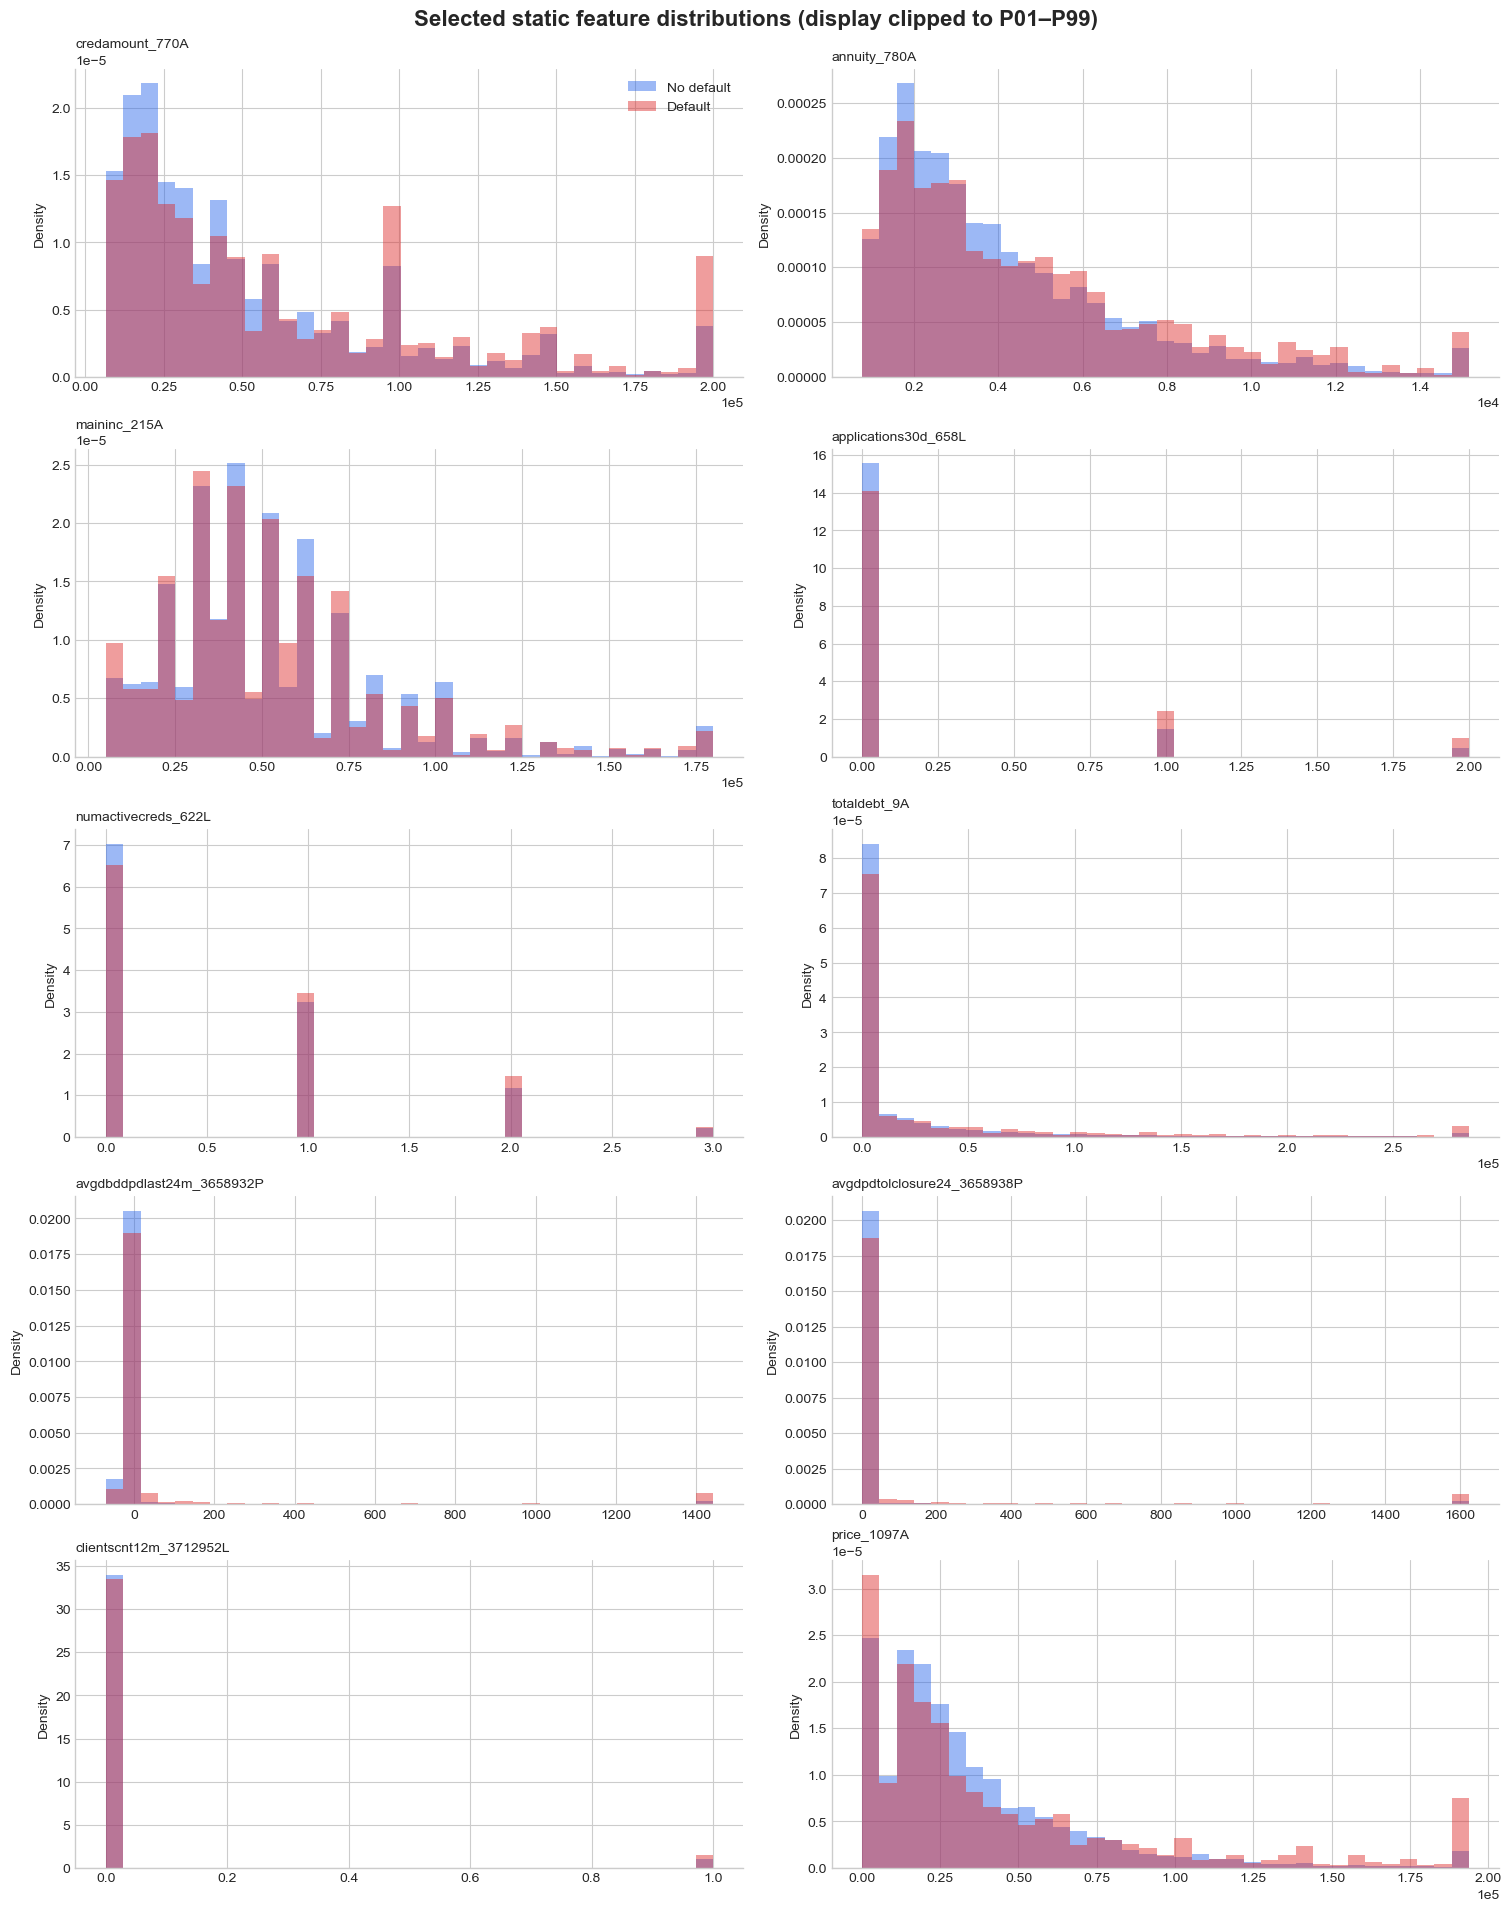

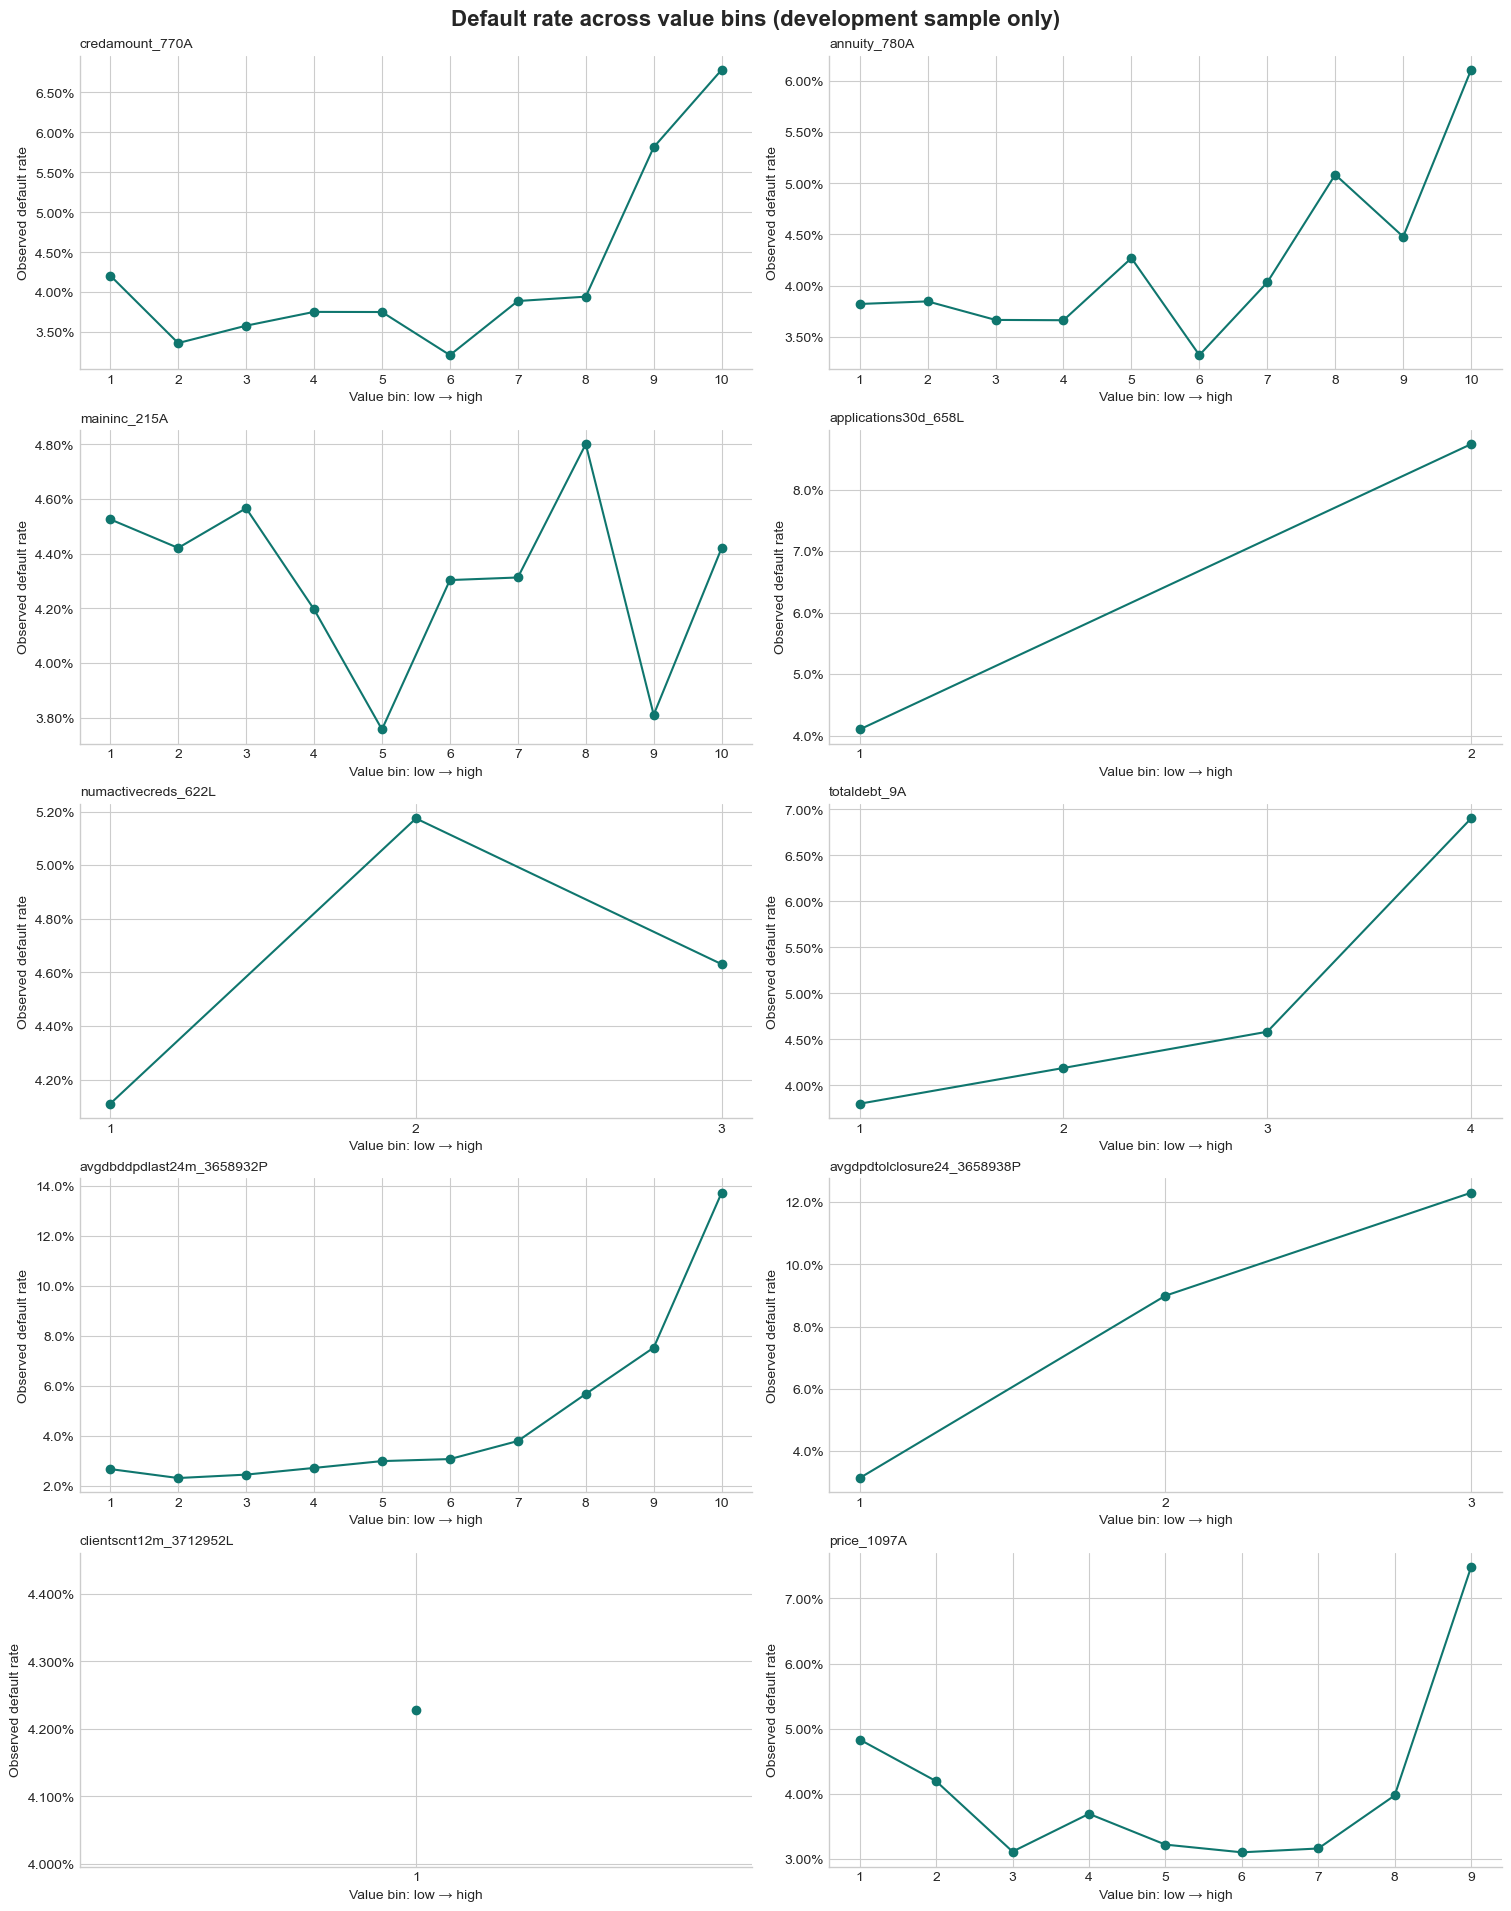

In [11]:
focus_features = [
    "credamount_770A",
    "annuity_780A",
    "maininc_215A",
    "applications30d_658L",
    "numactivecreds_622L",
    "totaldebt_9A",
    "avgdbddpdlast24m_3658932P",
    "avgdpdtolclosure24_3658938P",
    "clientscnt12m_3712952L",
    "price_1097A",
]
assert set(focus_features).issubset(data.columns)
plot_sample = eda_sample.loc[association_valid_mask].copy()

fig, axes = plt.subplots(5, 2, figsize=(15, 19), layout="constrained")
for ax, column in zip(axes.flat, focus_features):
    series = plot_sample[column].replace([np.inf, -np.inf], np.nan)
    valid = series.dropna()
    if valid.empty:
        ax.text(0.5, 0.5, "No observed values", ha="center", va="center")
    else:
        lower, upper = valid.quantile([0.01, 0.99])
        if lower == upper:
            lower, upper = valid.min(), valid.max()
        for target_value, color, label in [(0, "#2563EB", "No default"), (1, "#DC2626", "Default")]:
            values = series[plot_sample["target"] == target_value].dropna().clip(lower, upper)
            ax.hist(values, bins=35, density=True, alpha=0.45, color=color, label=label)
    ax.set_title(column, loc="left", fontsize=10)
    ax.set_ylabel("Density")
    ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, 4))
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(frameon=False)
fig.suptitle("Selected static feature distributions (display clipped to P01–P99)", fontsize=16, fontweight="bold")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(5, 2, figsize=(15, 19), layout="constrained")
for ax, column in zip(axes.flat, focus_features):
    temporary = plot_sample[[column, "target"]].dropna().copy()
    try:
        temporary["bin"] = pd.qcut(temporary[column], q=10, duplicates="drop")
        rates = temporary.groupby("bin", observed=True)["target"].agg(["mean", "size"])
        ax.plot(range(len(rates)), rates["mean"] * 100, marker="o", color="#0F766E")
        ax.set_xticks(range(len(rates)), [str(i + 1) for i in range(len(rates))])
        ax.set_xlabel("Value bin: low → high")
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    except ValueError:
        ax.text(0.5, 0.5, "Insufficient distinct values", ha="center", va="center")
    ax.set_title(column, loc="left", fontsize=10)
    ax.set_ylabel("Observed default rate")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Default rate across value bins (development sample only)", fontsize=16, fontweight="bold")
plt.show()
plt.close(fig)

## 4.8 Categorical and Boolean features

Masked category codes are labels, not quantities. We profile cardinality, the most frequent level, and the percentage of rows belonging to rare levels. For association, smoothed category target rates are learned in weeks 0–51 and evaluated in weeks 52–71. Unseen validation levels receive the early-period overall default rate.

In [12]:
MISSING_TOKEN = "__MISSING__"

def category_keys(series):
    return series.astype("string").fillna(MISSING_TOKEN)

def categorical_temporal_auc(column, smoothing=50):
    train_keys = category_keys(eda_sample.loc[association_train_mask, column])
    valid_keys = category_keys(eda_sample.loc[association_valid_mask, column])
    y_train_period = eda_sample.loc[association_train_mask, "target"]
    y_valid_period = eda_sample.loc[association_valid_mask, "target"]
    prior = y_train_period.mean()
    statistics = pd.DataFrame({"key": train_keys.to_numpy(), "target": y_train_period.to_numpy()}).groupby("key")["target"].agg(["sum", "count"])
    rates = (statistics["sum"] + smoothing * prior) / (statistics["count"] + smoothing)
    scores = valid_keys.map(rates).fillna(prior).to_numpy(dtype=float)
    return {
        "auc_valid": safe_binary_auc(y_valid_period, scores),
        "levels_train": len(statistics),
        "unseen_percent_valid": float((~valid_keys.isin(statistics.index)).mean() * 100),
    }

categorical_profile_rows = []
for column in categorical_columns:
    full_counts = data[column].value_counts(dropna=False)
    rare_threshold = max(100, int(len(data) * 0.0001))
    rare_rows = int(full_counts[full_counts < rare_threshold].sum())

    association = categorical_temporal_auc(column)

    categorical_profile_rows.append({
        "feature": column,
        "unique_non_null_full": int(data[column].nunique(dropna=True)),
        "missing_percent_full": float(data[column].isna().mean() * 100),
        "top_level_full": str(full_counts.index[0]) if len(full_counts) else None,
        "top_level_percent_full": float(full_counts.iloc[0] / len(data) * 100) if len(full_counts) else np.nan,
        "rare_row_percent_full": rare_rows / len(data) * 100,
        "levels_train_sample": association["levels_train"],
        "unseen_percent_valid_sample": association["unseen_percent_valid"],
        "auc_valid_smoothed_encoding": association["auc_valid"],
    })

categorical_profile = pd.DataFrame(categorical_profile_rows).set_index("feature")
display(categorical_profile.sort_values("auc_valid_smoothed_encoding", ascending=False).style.format({
    "missing_percent_full": "{:.2f}%",
    "top_level_percent_full": "{:.2f}%",
    "rare_row_percent_full": "{:.2f}%",
    "unseen_percent_valid_sample": "{:.2f}%",
    "auc_valid_smoothed_encoding": "{:.3f}",
}))

,unique_non_null_full,missing_percent_full,top_level_full,top_level_percent_full,rare_row_percent_full,levels_train_sample,unseen_percent_valid_sample,auc_valid_smoothed_encoding
feature,,,,,,,,
lastrejectreason_759M,18,0.00%,a55475b1,62.47%,0.02%,17,0.00%,0.620
lastrejectreasonclient_4145040M,14,0.00%,a55475b1,63.89%,0.00%,11,0.00%,0.606
lastst_736L,11,19.99%,D,25.30%,0.01%,10,0.00%,0.606
lastcancelreason_561M,74,0.00%,a55475b1,70.35%,0.10%,57,0.01%,0.585
opencred_647L,2,19.99%,False,76.68%,0.00%,3,0.00%,0.541
previouscontdistrict_112M,223,0.00%,a55475b1,31.99%,0.06%,199,0.28%,0.535
lastapprcommoditycat_1041M,45,0.00%,a55475b1,55.82%,0.06%,40,0.00%,0.527
lastrejectcommoditycat_161M,45,0.00%,a55475b1,79.65%,0.04%,38,0.00%,0.526
typesuite_864L,1,73.46%,nan,73.46%,0.00%,2,0.00%,0.524


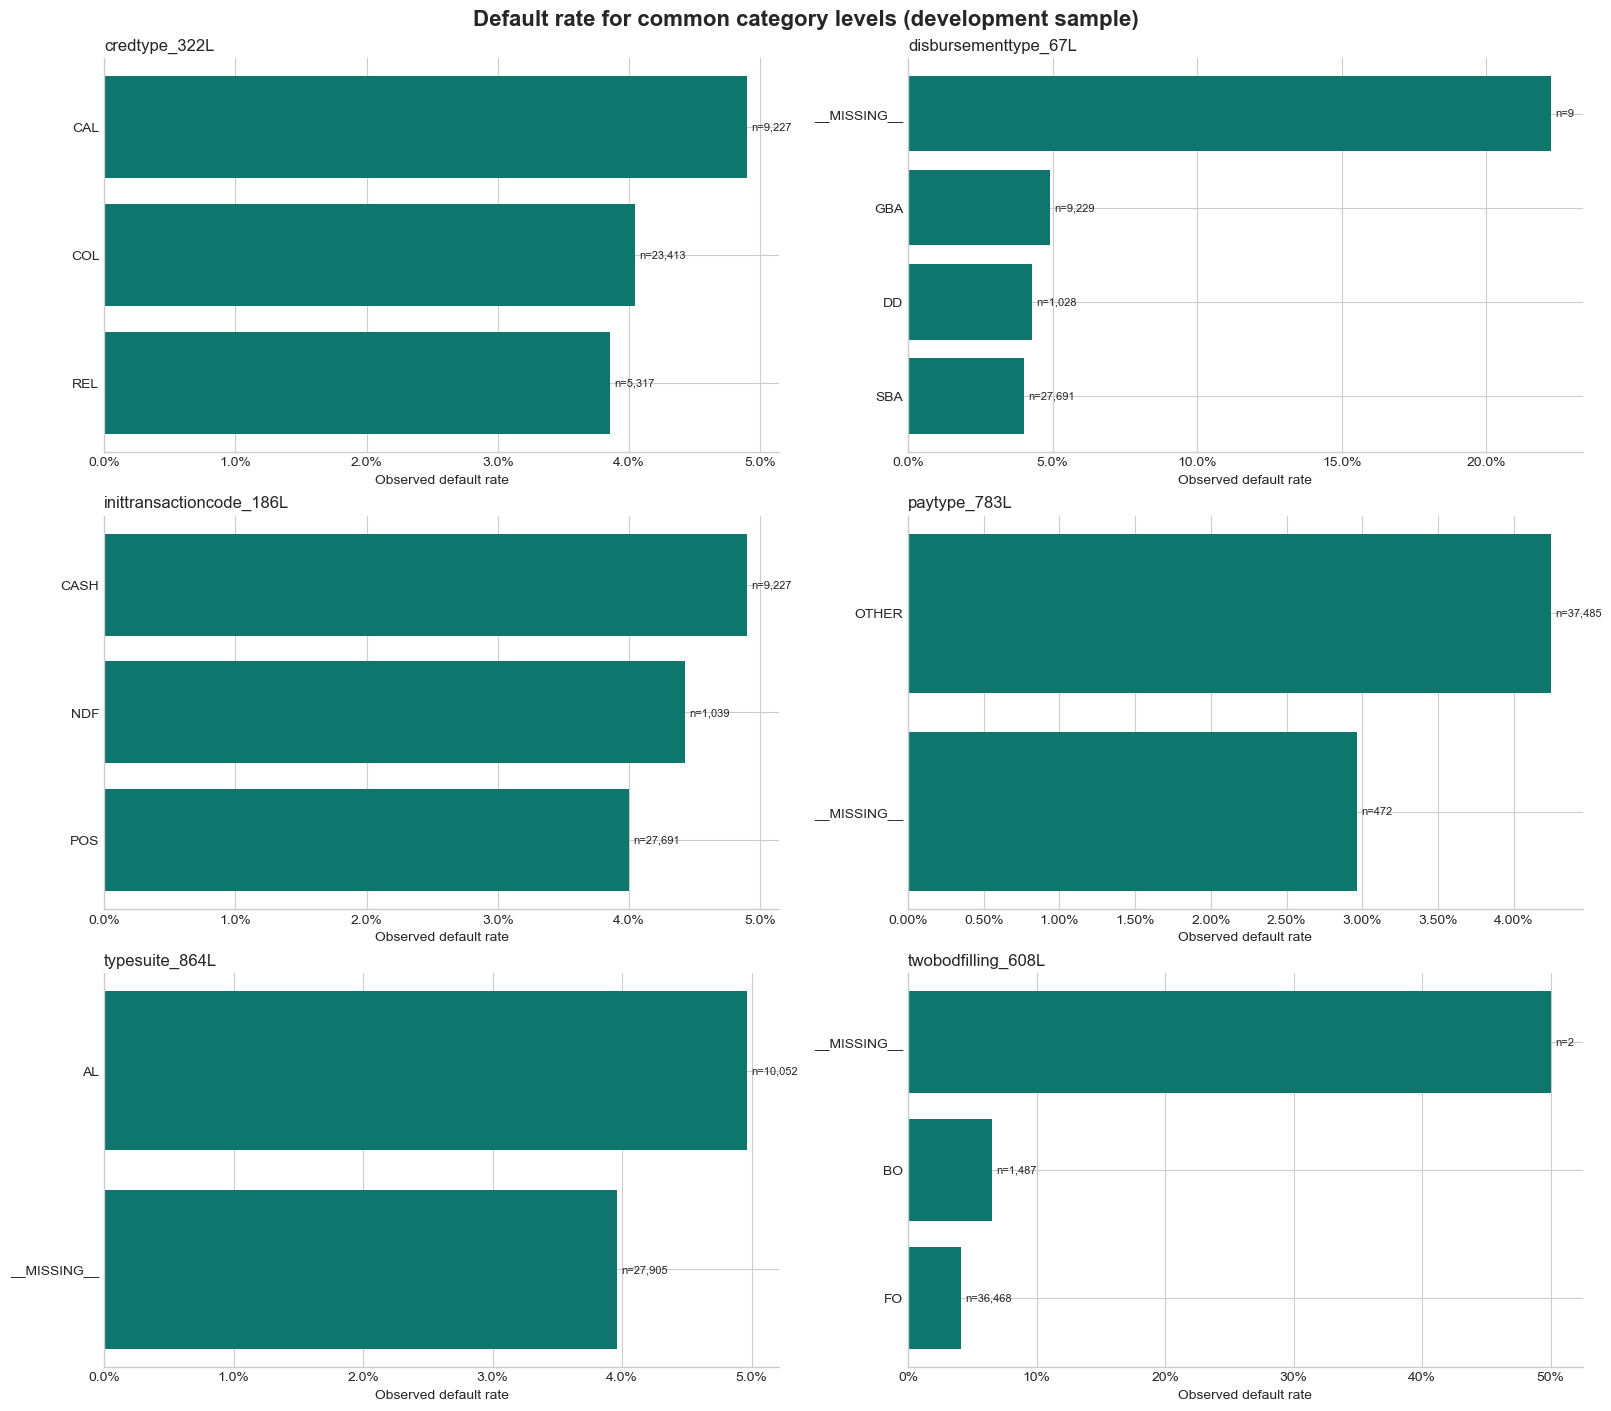

In [13]:
focus_categories = [column for column in [
    "credtype_322L",
    "disbursementtype_67L",
    "inittransactioncode_186L",
    "paytype_783L",
    "typesuite_864L",
    "twobodfilling_608L",
] if column in categorical_columns]

fig, axes = plt.subplots(3, 2, figsize=(16, 14), layout="constrained")
for ax, column in zip(axes.flat, focus_categories):
    levels = plot_sample[column].astype("object").where(plot_sample[column].notna(), "__MISSING__")
    top_levels = levels.value_counts().head(8).index
    temporary = pd.DataFrame({"level": levels, "target": plot_sample["target"]})
    summary = temporary[temporary["level"].isin(top_levels)].groupby("level")["target"].agg(["mean", "size"]).sort_values("mean")
    bars = ax.barh(summary.index.astype(str), summary["mean"] * 100, color="#0F766E")
    ax.bar_label(bars, labels=[f"n={n:,}" for n in summary["size"]], padding=3, fontsize=8)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.set_title(column, loc="left")
    ax.set_xlabel("Observed default rate")
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes.flat[len(focus_categories):]:
    ax.set_visible(False)
fig.suptitle("Default rate for common category levels (development sample)", fontsize=16, fontweight="bold")
plt.show()
plt.close(fig)

## 4.9 Date features and recency

Raw calendar dates can encourage a model to memorize a period. A more meaningful future feature is often **recency**: `date_decision − historical_date`. We audit every date column and flag dates after the application decision. Such dates require definition review; they are not automatically leakage or errors.

In [14]:
date_profile_rows = []
for column in date_columns:
    observed = data[column].notna()
    recency_days = (data.loc[observed, "date_decision"] - data.loc[observed, column]).dt.days
    sample_recency = (eda_sample["date_decision"] - eda_sample[column]).dt.days
    train_observed = association_train_mask & sample_recency.notna()
    valid_observed = association_valid_mask & sample_recency.notna()
    recency_auc_train = safe_binary_auc(eda_sample.loc[train_observed, "target"], sample_recency[train_observed])
    direction = 1 if pd.isna(recency_auc_train) or recency_auc_train >= 0.5 else -1
    recency_auc_valid = safe_binary_auc(eda_sample.loc[valid_observed, "target"], sample_recency[valid_observed] * direction)
    date_profile_rows.append({
        "feature": column,
        "missing_percent": float((~observed).mean() * 100),
        "earliest_date": data.loc[observed, column].min(),
        "latest_date": data.loc[observed, column].max(),
        "median_recency_days": recency_days.median(),
        "dates_after_decision_count": int((recency_days < 0).sum()),
        "dates_after_decision_percent_of_observed": float((recency_days < 0).mean() * 100) if len(recency_days) else np.nan,
        "observed_rows_train": int(train_observed.sum()),
        "observed_rows_valid": int(valid_observed.sum()),
        "recency_risk_direction_learned_train": "higher" if direction == 1 else "lower",
        "recency_auc_valid_oriented": recency_auc_valid,
    })

date_profile = pd.DataFrame(date_profile_rows).set_index("feature")
display(date_profile.sort_values("dates_after_decision_percent_of_observed", ascending=False).style.format({
    "missing_percent": "{:.2f}%",
    "median_recency_days": "{:,.0f}",
    "observed_rows_train": "{:,}",
    "observed_rows_valid": "{:,}",
    "dates_after_decision_count": "{:,}",
    "dates_after_decision_percent_of_observed": "{:.2f}%",
    "recency_auc_valid_oriented": "{:.3f}",
}))

,missing_percent,earliest_date,latest_date,median_recency_days,dates_after_decision_count,dates_after_decision_percent_of_observed,observed_rows_train,observed_rows_valid,recency_risk_direction_learned_train,recency_auc_valid_oriented
feature,,,,,,,,,,
lastrepayingdate_696D,99.84%,2007-04-05 00:00:00,2020-10-18 00:00:00,-11,"1,979",83.26%,267,60,higher,0.739
validfrom_1069D,90.06%,2018-09-22 00:00:00,2020-06-22 00:00:00,9,"54,689",36.03%,"18,763","3,816",lower,0.537
dtlastpmtallstes_4499206D,64.00%,2006-02-22 00:00:00,2020-10-18 00:00:00,42,"126,627",23.04%,"42,583","22,184",lower,0.519
lastapplicationdate_877D,19.99%,2006-01-03 00:00:00,2020-10-19 00:00:00,217,"114,236",9.35%,"126,646","31,619",lower,0.580
firstclxcampaign_1125D,56.28%,2016-01-31 00:00:00,2020-06-23 00:00:00,"1,116","37,006",5.54%,"69,742","16,983",lower,0.600
lastdelinqdate_224D,64.06%,2006-08-19 00:00:00,2020-10-18 00:00:00,297,"29,245",5.33%,"54,160","14,984",lower,0.556
lastrejectdate_50D,50.37%,2006-01-03 00:00:00,2020-10-19 00:00:00,436,"38,799",5.12%,"76,414","20,584",lower,0.596
datelastunpaid_3546854D,58.14%,2006-02-08 00:00:00,2020-10-18 00:00:00,425,"28,221",4.42%,"64,063","17,145",lower,0.565
lastapprdate_640D,28.95%,2006-01-07 00:00:00,2020-10-19 00:00:00,297,"34,241",3.16%,"111,833","28,135",higher,0.474


## 4.10 Time stability and feature drift

We compare weeks 0–51 with the later development period, weeks 52–71. Numerical features use the two-sample Kolmogorov–Smirnov (KS) statistic; categories use total-variation distance; dates use KS on recency. Both scores range from 0 to 1, where larger values mean a larger sample distribution difference. Missingness shift is reported separately.

These scores rank investigation priorities. There is no universal cutoff that proves a feature is unusable.

In [15]:
development_min_week = 0
early_end_week = 51
late_start_week = 52
development_max_week = 71
early_sample = eda_sample.loc[association_train_mask]
late_sample = eda_sample.loc[association_valid_mask]

def total_variation_distance(left, right):
    left_values = left.astype("object").where(left.notna(), "__MISSING__")
    right_values = right.astype("object").where(right.notna(), "__MISSING__")
    levels = pd.Index(left_values.unique()).union(pd.Index(right_values.unique()))
    left_p = left_values.value_counts(normalize=True).reindex(levels, fill_value=0)
    right_p = right_values.value_counts(normalize=True).reindex(levels, fill_value=0)
    return float(0.5 * np.abs(left_p - right_p).sum())

drift_rows = []
for column in feature_columns:
    kind = feature_kind(column)
    early_missing = early_sample[column].isna().mean() * 100
    late_missing = late_sample[column].isna().mean() * 100

    if kind == "numeric":
        early_values = early_sample[column].replace([np.inf, -np.inf], np.nan).dropna()
        late_values = late_sample[column].replace([np.inf, -np.inf], np.nan).dropna()
        drift_score = ks_2samp(early_values, late_values).statistic if len(early_values) and len(late_values) else np.nan
        measure = "KS numeric"
    elif kind == "date":
        early_values = (early_sample["date_decision"] - early_sample[column]).dt.days.dropna()
        late_values = (late_sample["date_decision"] - late_sample[column]).dt.days.dropna()
        drift_score = ks_2samp(early_values, late_values).statistic if len(early_values) and len(late_values) else np.nan
        measure = "KS recency"
    else:
        drift_score = total_variation_distance(early_sample[column], late_sample[column])
        measure = "Total variation"

    drift_rows.append({
        "feature": column,
        "kind": kind,
        "measure": measure,
        "distribution_drift_score": drift_score,
        "early_missing_percent": early_missing,
        "late_missing_percent": late_missing,
        "missing_shift_percentage_points": late_missing - early_missing,
    })

temporal_drift = pd.DataFrame(drift_rows).set_index("feature")
temporal_drift["investigation_priority"] = np.maximum(
    temporal_drift["distribution_drift_score"].fillna(0),
    temporal_drift["missing_shift_percentage_points"].abs() / 100,
)

print(f"Early comparison window: weeks {development_min_week}–{early_end_week} ({len(early_sample):,} sampled rows)")
print(f"Late comparison window: weeks {late_start_week}–{development_max_week} ({len(late_sample):,} sampled rows)")
display(temporal_drift.nlargest(25, "investigation_priority").style.format({
    "distribution_drift_score": "{:.3f}",
    "early_missing_percent": "{:.2f}%",
    "late_missing_percent": "{:.2f}%",
    "missing_shift_percentage_points": "{:+.2f}",
    "investigation_priority": "{:.3f}",
}))

Early comparison window: weeks 0–51 (162,043 sampled rows)
Late comparison window: weeks 52–71 (37,957 sampled rows)


,kind,measure,distribution_drift_score,early_missing_percent,late_missing_percent,missing_shift_percentage_points,investigation_priority
feature,,,,,,,
numinstmatpaidtearly2d_4499204L,numeric,KS numeric,0.038,68.81%,26.52%,-42.29,0.423
numinstpaid_4499208L,numeric,KS numeric,0.053,68.81%,26.52%,-42.29,0.423
numinstpaidearly5dobd_4499205L,numeric,KS numeric,0.029,68.81%,26.52%,-42.29,0.423
numinstpaidearly3dest_4493216L,numeric,KS numeric,0.036,68.16%,26.52%,-41.64,0.416
numinstpaidearly5dest_4493211L,numeric,KS numeric,0.028,68.16%,26.52%,-41.64,0.416
numinstpaidearlyest_4493214L,numeric,KS numeric,0.028,68.16%,26.52%,-41.64,0.416
numinstregularpaidest_4493210L,numeric,KS numeric,0.051,68.16%,26.52%,-41.64,0.416
numinsttopaygrest_4493213L,numeric,KS numeric,0.041,68.16%,26.52%,-41.64,0.416
numinstunpaidmaxest_4493212L,numeric,KS numeric,0.042,68.16%,26.52%,-41.64,0.416


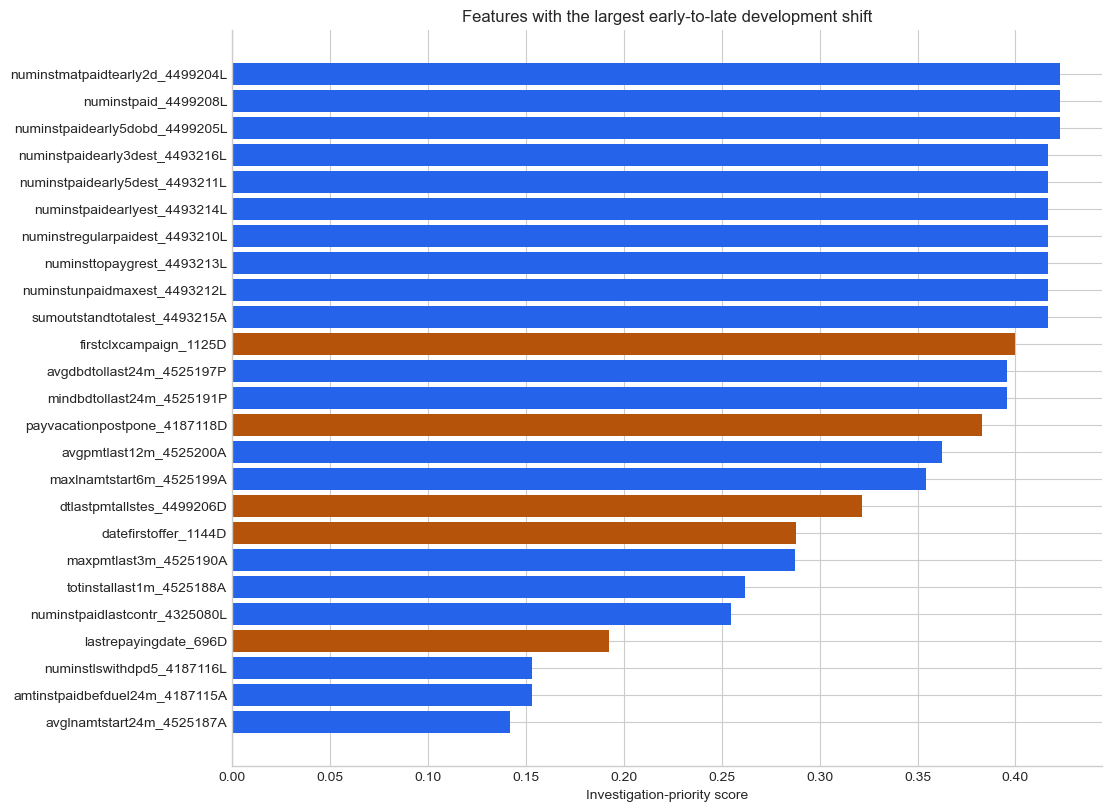

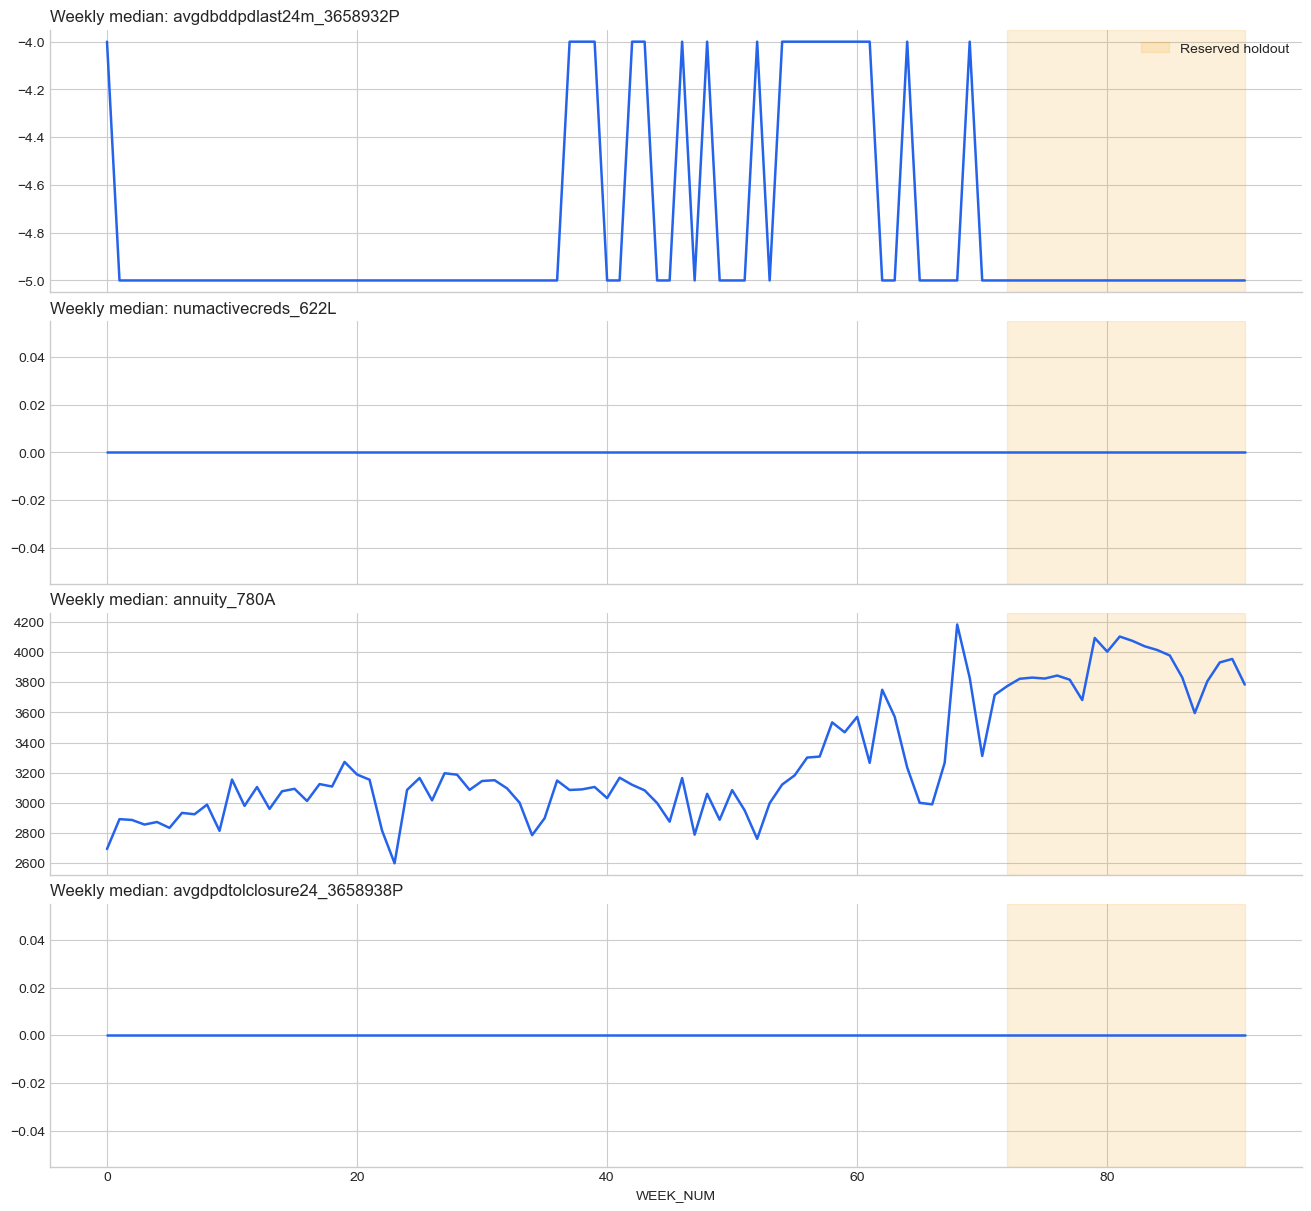

In [16]:
top_drift = temporal_drift.nlargest(25, "investigation_priority").sort_values("investigation_priority")
colors = top_drift["kind"].map({
    "numeric": "#2563EB",
    "date": "#B45309",
    "categorical": "#7C3AED",
    "boolean": "#0F766E",
})
fig, ax = plt.subplots(figsize=(11, 8), layout="constrained")
ax.barh(top_drift.index, top_drift["investigation_priority"], color=colors)
ax.set(title="Features with the largest early-to-late development shift", xlabel="Investigation-priority score")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
plt.close(fig)

weekly_focus = temporal_drift.loc[focus_features].nlargest(4, "investigation_priority").index.tolist()
fig, axes = plt.subplots(len(weekly_focus), 1, figsize=(13, 3 * len(weekly_focus)), sharex=True, layout="constrained")
axes = np.atleast_1d(axes)
for ax, column in zip(axes, weekly_focus):
    weekly = data.groupby("WEEK_NUM")[column].median()
    ax.plot(weekly.index, weekly.values, color="#2563EB", linewidth=1.8)
    ax.axvspan(holdout_start_week, maximum_week, color="#F59E0B", alpha=0.15, label="Reserved holdout")
    ax.set_title(f"Weekly median: {column}", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
axes[-1].set_xlabel("WEEK_NUM")
plt.show()
plt.close(fig)

## 4.11 Numerical redundancy

Highly correlated features may contain nearly the same information. We calculate Spearman correlations on a 50,000-row development sample and list pairs with absolute correlation of at least 0.98. Correlation alone does not require deleting either feature, especially for tree models.

Numerical pairs with |Spearman correlation| ≥ 0.98: 31


,feature_1,feature_2,spearman_correlation,absolute_correlation
3901,disbursedcredamount_1113A,inittransactionamount_650A,+1.000,1.000
4055,eir_270L,interestrate_311L,+1.000,1.000
6591,numinstpaidearly_338L,numinstpaidearlyest_4493214L,+1.000,1.000
7016,sumoutstandtotal_3546847A,sumoutstandtotalest_4493215A,+1.000,1.000
6562,numinstpaidearly5dobd_4499205L,numinstpaidearlyest_4493214L,+1.000,1.000
6561,numinstpaidearly5dobd_4499205L,numinstpaidearly_338L,+1.000,1.000
6498,numinstpaidearly5d_1087L,numinstpaidearly5dest_4493211L,+1.000,1.000
6406,numinstpaid_4499208L,numinstregularpaidest_4493210L,+1.000,1.000
3734,currdebt_22A,totaldebt_9A,+1.000,1.000
6405,numinstpaid_4499208L,numinstregularpaid_973L,+1.000,1.000


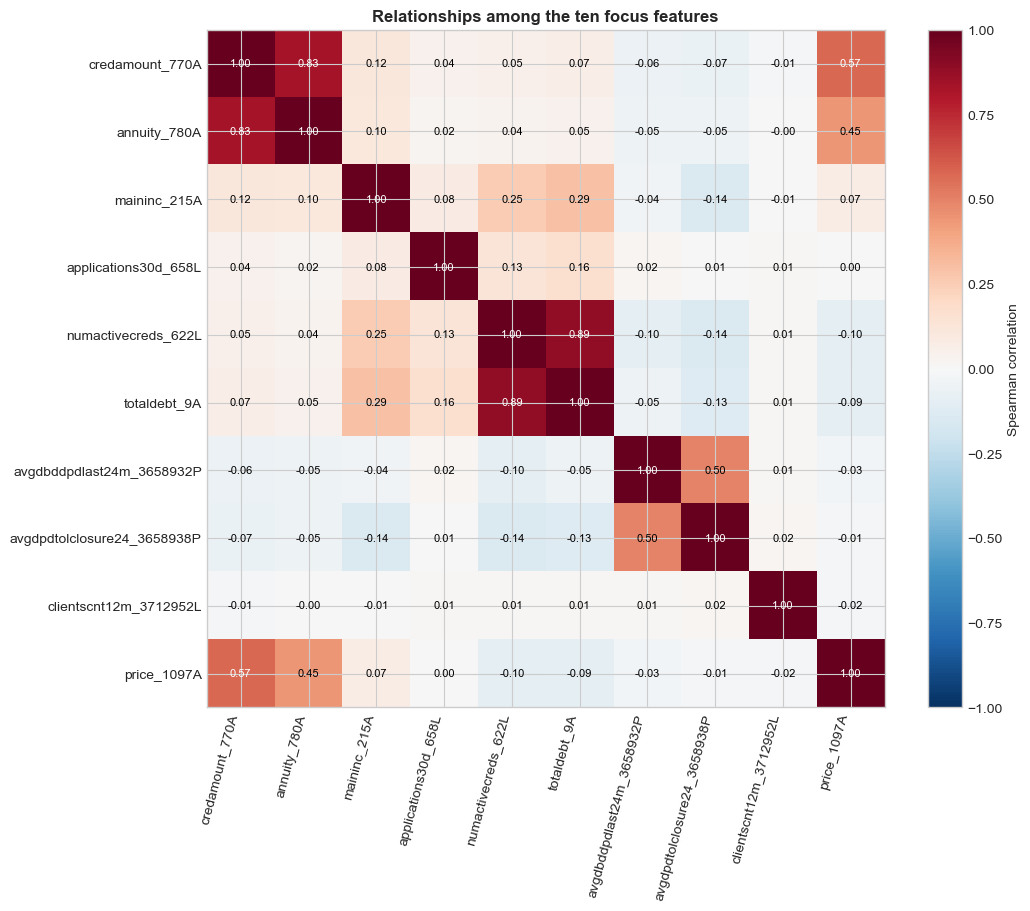

In [17]:
correlation_sample = eda_sample[numeric_columns].sample(
    n=min(CORRELATION_SAMPLE_SIZE, len(eda_sample)),
    random_state=RANDOM_STATE,
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    correlation_matrix = correlation_sample.corr(method="spearman", min_periods=1_000)
upper_triangle = np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1)
correlation_pairs = (
    correlation_matrix.where(upper_triangle)
    .stack()
    .rename("spearman_correlation")
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
)
correlation_pairs["absolute_correlation"] = correlation_pairs["spearman_correlation"].abs()
high_correlation_pairs = correlation_pairs[
    correlation_pairs["absolute_correlation"] >= 0.98
].sort_values("absolute_correlation", ascending=False)

print(f"Numerical pairs with |Spearman correlation| ≥ 0.98: {len(high_correlation_pairs):,}")
display(high_correlation_pairs.head(30).style.format({
    "spearman_correlation": "{:+.3f}",
    "absolute_correlation": "{:.3f}",
}))

focus_correlation = eda_sample[focus_features].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
image = ax.imshow(focus_correlation, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(focus_features)), focus_features, rotation=75, ha="right")
ax.set_yticks(range(len(focus_features)), focus_features)
for row in range(len(focus_features)):
    for column_index in range(len(focus_features)):
        value = focus_correlation.iloc[row, column_index]
        ax.text(column_index, row, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(value) > 0.55 else "black")
fig.colorbar(image, ax=ax, label="Spearman correlation")
ax.set_title("Relationships among the ten focus features", fontweight="bold")
plt.show()
plt.close(fig)

## 4.12 Reusable single-feature inspector

Use this helper to investigate any of the 167 features without opening the raw file in Excel. It prints the official definition and catalog record, then draws an appropriate development-sample view.

Feature: totaldebt_9A
Meaning: Total amount of debt.


,description,suffix,kind,pandas_dtype,non_null_count,missing_count,missing_percent,unique_non_null,sample_dominant_percent
feature,,,,,,,,,
totaldebt_9A,Total amount of debt.,A,numeric,float64,1526656,3,0.000197,363903,67.0885


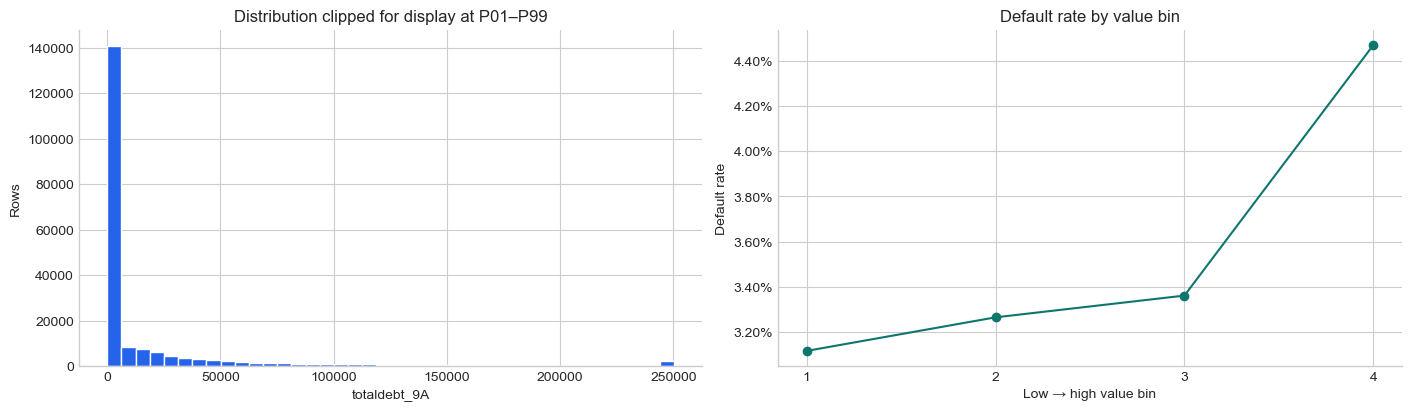

In [18]:
def inspect_feature(column):
    if column not in feature_columns:
        raise KeyError(f"Unknown static_0 feature: {column}")

    print(f"Feature: {column}")
    print(f"Meaning: {description_map.get(column, 'Description unavailable')}")
    display(feature_catalog.loc[[column]])
    kind = feature_kind(column)

    if kind == "numeric":
        values = eda_sample[column].replace([np.inf, -np.inf], np.nan)
        observed = values.dropna()
        if observed.empty:
            print("No observed values in the development sample.")
            return
        lower, upper = observed.quantile([0.01, 0.99])
        clipped = values.clip(lower, upper)
        fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
        axes[0].hist(clipped.dropna(), bins=40, color="#2563EB", edgecolor="white")
        axes[0].set(title="Distribution clipped for display at P01–P99", xlabel=column, ylabel="Rows")
        temporary = eda_sample[[column, "target"]].dropna().copy()
        try:
            temporary["bin"] = pd.qcut(temporary[column], 10, duplicates="drop")
            summary = temporary.groupby("bin", observed=True)["target"].mean()
            axes[1].plot(range(len(summary)), summary * 100, marker="o", color="#0F766E")
            axes[1].set_xticks(range(len(summary)), range(1, len(summary) + 1))
            axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100))
            axes[1].set(title="Default rate by value bin", xlabel="Low → high value bin", ylabel="Default rate")
        except ValueError:
            axes[1].text(0.5, 0.5, "Insufficient distinct values", ha="center", va="center")
    elif kind in {"categorical", "boolean"}:
        levels = eda_sample[column].astype("object").where(eda_sample[column].notna(), "__MISSING__")
        top_levels = levels.value_counts().head(12).index
        temporary = pd.DataFrame({"level": levels, "target": eda_sample["target"]})
        summary = temporary[temporary["level"].isin(top_levels)].groupby("level")["target"].agg(["size", "mean"]).sort_values("size")
        fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
        axes[0].barh(summary.index.astype(str), summary["size"], color="#2563EB")
        axes[0].set(title="Most common levels", xlabel="Sample rows")
        axes[1].barh(summary.index.astype(str), summary["mean"] * 100, color="#0F766E")
        axes[1].xaxis.set_major_formatter(PercentFormatter(xmax=100))
        axes[1].set(title="Observed default rate", xlabel="Default rate")
    else:
        recency = (eda_sample["date_decision"] - eda_sample[column]).dt.days.dropna()
        fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
        if len(recency):
            lower, upper = recency.quantile([0.01, 0.99])
            ax.hist(recency.clip(lower, upper), bins=40, color="#B45309", edgecolor="white")
        ax.set(title="Recency from application decision (P01–P99 display)", xlabel="Days: decision date − feature date", ylabel="Rows")
        axes = [ax]

    for ax in np.atleast_1d(axes):
        ax.spines[["top", "right"]].set_visible(False)
    plt.show()
    plt.close(fig)

inspect_feature("totaldebt_9A")

## 4.13 Export compact reports and create an engineering disposition

The notebook saves summary reports, not another multi-gigabyte copy of the dataset. The generated lists are starting points:

- **Provisional candidates:** no severe structural flag found.
- **Investigate:** high missingness, near-constant behavior, large drift, or dates after decision.
- **Exclude from the first baseline:** constants, almost entirely missing columns, and raw date columns. Dates can return later as carefully validated recency features.

In [19]:
feature_catalog = feature_catalog.join(
    missing_target_signal[["missing_target_gap_train_pp", "missing_target_gap_valid_pp", "missing_indicator_auc_valid_oriented"]], how="left"
).join(
    temporal_drift[["distribution_drift_score", "missing_shift_percentage_points", "investigation_priority"]], how="left"
)

almost_empty_features = feature_catalog.index[feature_catalog["missing_percent"] >= 99].tolist()
high_cardinality_categories = categorical_profile.index[
    categorical_profile["unique_non_null_full"] > 100
].tolist()
dates_after_decision = date_profile.index[date_profile["dates_after_decision_count"] > 0].tolist()
large_drift_features = temporal_drift.index[temporal_drift["investigation_priority"] >= 0.20].tolist()

first_baseline_exclusions = sorted(set(
    complete_constant_features + almost_empty_features + date_columns
))
investigate_features = sorted(set(
    feature_catalog.index[feature_catalog["missing_percent"] >= 80].tolist()
    + near_constant_features
    + dates_after_decision
    + large_drift_features
    + high_cardinality_categories
))
provisional_candidates = sorted(set(feature_columns) - set(first_baseline_exclusions))

feature_catalog.to_csv(report_dir / "static_0_feature_catalog.csv")
numeric_profile.join(numeric_target_profile, how="left").to_csv(report_dir / "numeric_profile.csv")
categorical_profile.to_csv(report_dir / "categorical_profile.csv")
date_profile.to_csv(report_dir / "date_profile.csv")
missing_target_signal.to_csv(report_dir / "missingness_target_signal.csv")
temporal_drift.to_csv(report_dir / "temporal_drift.csv")
high_correlation_pairs.to_csv(report_dir / "high_correlation_pairs.csv", index=False)

disposition = pd.DataFrame({
    "group": ["Provisional candidates", "Investigate", "Exclude from first baseline"],
    "feature_count": [len(provisional_candidates), len(investigate_features), len(first_baseline_exclusions)],
    "examples": [
        ", ".join(provisional_candidates[:12]),
        ", ".join(investigate_features[:12]),
        ", ".join(first_baseline_exclusions[:12]),
    ],
})
display(disposition)
print(f"Reports saved to: {report_dir}")
print("No source data was modified.")

,group,feature_count,examples
0,Provisional candidates,147,"actualdpdtolerance_344P, amtinstpaidbefduel24m_4187115A, annuity_780A, annuitynextmonth_57A, app..."
1,Investigate,54,"applicationcnt_361L, avgdbdtollast24m_4525197P, avglnamtstart24m_4525187A, avgpmtlast12m_4525200..."
2,Exclude from first baseline,20,"clientscnt_136L, datefirstoffer_1144D, datelastinstal40dpd_247D, datelastunpaid_3546854D, deferr..."


Reports saved to: D:\Home Credit - Credit Risk Model Stability\reports\static_0_eda
No source data was modified.


## Engineering conclusions and next step

This notebook has completed the structural and exploratory audit of `static_0`. Its reports help us identify data-quality questions, possible missingness signals, skewed numerical features, category behavior, date-recency opportunities, time drift, and redundant numerical pairs.

No imputation, scaling, clipping, category grouping, or feature selection has been permanently applied. In the next modeling notebook we will:

1. create expanding-window cross-validation within the development weeks;
2. fit preprocessing separately inside every training fold;
3. train a simple logistic-regression baseline;
4. evaluate ROC AUC, Gini, calibration, and weekly stability; and
5. use the reserved final twenty weeks once for the final local check.

The official dataset description identifies `static_0` as depth-0 internal data directly tied to `case_id`: https://www.kaggle.com/c/home-credit-credit-risk-model-stability/data